# Sesión 10 · Notebook de clase · Describir una variable

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Semana 5 · Unidad 3: tema 3.3, análisis univariado (descriptivos, tablas de frecuencia, histogramas, diagramas de caja y barras) con **matplotlib**.

Hasta hoy respondimos preguntas **agrupando** (sesión 8) y **preparando** las tablas (sesión 9). Antes de comparar variables entre sí (sesión 11) hay que conocer cada una **por separado**: dónde está su centro, cuánto se dispersa, qué forma tiene, si hay valores extremos. Eso es el análisis **univariado**, y es la sección de descripción de la Entrega 1.

Datos de hoy, en la carpeta `datos/`:

| Archivo | Qué es |
| :-- | :-- |
| `cosechas.csv` | 480 ciclos de cosecha de camarón (2024–2025): zona, laboratorio, días, hectáreas, densidad, supervivencia, peso, cosecha, alimento, precio. Nuevo. |
| `ventas_completo.csv` | las 260 ventas de enero a abril que dejó la sesión 9 (con región, costo y margen) |

**Cómo trabajar con este notebook**
- Ejecute las celdas en orden. En los ejercicios **Su turno**, reemplace los `...`; la celda `assert` siguiente comprueba el resultado.
- Los gráficos se dibujan con matplotlib. En Jupyter aparecen debajo de la celda; no hace falta `plt.show()`, pero no estorba.
- Las salidas de la versión resuelta están en pandas 3 (texto con tipo `str`; en pandas 2 aparece `object`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

c = pd.read_csv("datos/cosechas.csv", parse_dates=["fecha_siembra"])
v = pd.read_csv("datos/ventas_completo.csv", parse_dates=["fecha"])
print("cosechas:", c.shape, "| ventas:", v.shape)
c.head()

cosechas: (480, 13) | ventas: (260, 13)


,ciclo,piscina,zona,laboratorio,fecha_siembra,dias,hectareas,densidad,supervivencia,peso_g,cosecha_kg,alimento_kg,precio_kg
0,C-0001,P323,Guayas,Lab Costa,2024-01-05,118,6.8,13,69.8,25.4,15673,25822,5.49
1,C-0002,P170,El Oro,Lab Norte,2024-01-06,103,10.9,13,63.0,21.0,18747,28098,5.98
2,C-0003,P327,Guayas,Lab Sur,2024-01-11,113,5.4,18,68.5,20.5,13649,19611,4.82
3,C-0004,P369,Guayas,Lab Sur,2024-01-11,103,7.7,19,67.1,13.3,13056,22240,4.04
4,C-0005,P170,El Oro,Lab Norte,2024-01-13,91,6.4,11,71.2,19.7,9875,13974,4.36


In [2]:
c.dtypes

ciclo                       str
piscina                     str
zona                        str
laboratorio                 str
fecha_siembra    datetime64[us]
dias                      int64
hectareas               float64
densidad                  int64
supervivencia           float64
peso_g                  float64
cosecha_kg                int64
alimento_kg               int64
precio_kg               float64
dtype: object

## 1. Cada tipo de variable tiene su resumen y su gráfico

Lo primero (sesión 3) es saber **qué tipo de variable** es cada columna. El tipo decide el resumen y el gráfico:

| Tipo de variable | Ejemplo en `cosechas` | Resumen numérico | Gráfico |
| :-- | :-- | :-- | :-- |
| numérica **continua** | `peso_g`, `supervivencia`, `cosecha_kg` | media, mediana, desviación, cuartiles, mínimo y máximo | histograma, diagrama de caja |
| numérica **discreta** (pocos valores) | `densidad`, `dias` | lo mismo, o una tabla de frecuencias si los valores son pocos | barras (o histograma) |
| categórica **nominal** | `zona`, `laboratorio` | frecuencias absolutas y relativas, moda | barras (ordenadas por frecuencia) |
| categórica **ordinal** | `tamano` (en ventas) | frecuencias **en su orden** | barras (en su orden) |
| fecha | `fecha_siembra` | conteo por período (sesión 12) | línea en el tiempo (sesión 12) |

Un identificador (`ciclo`, `piscina`) no se resume: su «promedio» no significa nada. Lo mismo pasa con un código numérico (recuerde la Lección 1).

`describe()` da el resumen de todas las numéricas de una vez; con `include="object"` (o `"str"` en pandas 3) resume las de texto: cuántos valores distintos y cuál es el más frecuente.

In [3]:
c.describe().round(2)

,fecha_siembra,dias,hectareas,densidad,supervivencia,peso_g,cosecha_kg,alimento_kg,precio_kg
count,480,480.00,480.00,480.00,480.00,480.00,480.00,480.00,480.00
mean,2024-11-18 09:42:00,107.84,8.96,13.98,66.64,19.78,16645.68,24753.71,5.48
min,2024-01-05 00:00:00,85.00,2.10,6.00,18.70,10.70,2658.00,3810.00,3.59
25%,2024-06-21 00:00:00,97.00,5.98,12.00,60.08,17.50,9388.75,13781.50,5.03
50%,2024-11-24 00:00:00,108.50,8.00,14.00,66.75,19.65,14048.00,21355.00,5.48
75%,2025-04-09 12:00:00,119.25,10.92,16.00,73.40,21.92,20973.50,30773.75,5.92
max,2025-10-05 00:00:00,130.00,52.00,22.00,90.50,29.10,146286.00,212115.00,7.25
std,NaN,13.32,4.46,3.35,9.87,3.17,11259.38,16896.04,0.65


In [4]:
# Las columnas de texto: cuántos valores distintos (unique), el más frecuente (top) y cuántas veces aparece (freq)
c[["zona", "laboratorio", "piscina"]].describe()

,zona,laboratorio,piscina
count,480,480,480
unique,5,4,244
top,Guayas,Lab Norte,P217
freq,205,157,6


## 2. Centro y dispersión de una variable numérica

**Centro.** La **media** (`mean`) suma todo y divide; la **mediana** (`median`) es el valor del medio: la mitad de los datos está por debajo. Cuando hay valores muy grandes la media se va hacia ellos y la mediana no; por eso **media > mediana** avisa de una **cola a la derecha** (asimetría positiva). La **moda** (`mode`) es el valor más repetido: solo tiene sentido en discretas y categóricas.

**Dispersión.** La **desviación estándar** (`std`) es la distancia típica a la media, en las mismas unidades que la variable. Los **cuartiles** (`quantile(0.25)`, `quantile(0.75)`) encierran la mitad central de los datos; su diferencia es el **rango intercuartílico (IQR)**, la medida de dispersión que no se deja arrastrar por los extremos (la usamos en la sesión 7 para detectar atípicos). El **rango** (`max − min`) depende solo de dos valores: es el más frágil.

**Forma.** `skew()` mide la asimetría: cerca de 0, simétrica; positiva, cola a la derecha; negativa, cola a la izquierda. Lo confirmamos con el histograma (sección 5).

In [5]:
col = c["cosecha_kg"]
print("media   :", round(col.mean(), 1))
print("mediana :", round(col.median(), 1), "  <- la media está muy por encima: cola a la derecha")
print("desv.   :", round(col.std(), 1))
print("Q1, Q3  :", col.quantile(0.25), col.quantile(0.75), " IQR =", col.quantile(0.75) - col.quantile(0.25))
print("mín, máx:", col.min(), col.max())
print("asimetría (skew):", round(col.skew(), 2))

media   : 16645.7
mediana : 14048.0   <- la media está muy por encima: cola a la derecha
desv.   : 11259.4
Q1, Q3  : 9388.75 20973.5  IQR = 11584.75
mín, máx: 2658 146286
asimetría (skew): 4.06


In [6]:
# La misma idea para varias columnas de una vez: el resumen que irá en la Entrega 1
resumen = c[["dias", "supervivencia", "peso_g", "cosecha_kg"]].agg(["mean", "median", "std", "min", "max", "skew"]).round(2)
resumen

,dias,supervivencia,peso_g,cosecha_kg
mean,107.84,66.64,19.78,16645.68
median,108.50,66.75,19.65,14048.00
std,13.32,9.87,3.17,11259.38
min,85.00,18.70,10.70,2658.00
max,130.00,90.50,29.10,146286.00
skew,-0.09,-0.44,0.05,4.06


In [7]:
# Moda: solo para discretas y categóricas. mode() devuelve una Series (puede haber empates).
print("días de cultivo más frecuente:", c["dias"].mode().tolist(), "| zona más frecuente:", c["zona"].mode().tolist())

días de cultivo más frecuente: [116] | zona más frecuente: ['Guayas']


### Su turno 2.1 · 4 min
Complete el diccionario `desc_sup` con los descriptivos de `supervivencia`, redondeados a 2 decimales: media, mediana, desviación estándar, primer y tercer cuartil. ¿La media y la mediana están cerca? ¿Qué dice eso de la forma?

In [8]:
# TODO: reemplace los ... por su código
s = c["supervivencia"]
desc_sup = {"media": round(s.mean(), 2), "mediana": round(s.median(), 2), "desv": round(s.std(), 2), "q1": round(s.quantile(0.25), 2), "q3": round(s.quantile(0.75), 2)}
desc_sup

{'media': np.float64(66.64),
 'mediana': np.float64(66.75),
 'desv': np.float64(9.87),
 'q1': np.float64(60.08),
 'q3': np.float64(73.4)}

In [9]:
assert {k: round(float(x), 2) for k, x in desc_sup.items()} == {'media': 66.64, 'mediana': 66.75, 'desv': 9.87, 'q1': 60.08, 'q3': 73.4}, "revise: mean, median, std, quantile(0.25), quantile(0.75), redondeados a 2 decimales"
print("Correcto. Media y mediana casi iguales: supervivencia es aproximadamente simétrica (skew =", round(s.skew(), 2), ").")

Correcto. Media y mediana casi iguales: supervivencia es aproximadamente simétrica (skew = -0.44 ).


## 3. Variables categóricas: tablas de frecuencia

Para una categórica el resumen es **cuántas veces aparece cada valor**: la frecuencia absoluta (`value_counts()`) y la relativa (`value_counts(normalize=True)`, que suma 1; multiplicada por 100, porcentaje). Las dos juntas, en una tabla, son la **tabla de frecuencias**.

- Nominal (`zona`): se presenta **ordenada por frecuencia** (lo que hace `value_counts` por defecto).
- Ordinal (`tamano`): se presenta **en su orden** (`sort_index()` si la columna es `category` ordenada, o `reindex([...])` con el orden a mano).
- Una numérica también se puede tabular por **intervalos** con `cut` (sesión 9): eso es, en forma de tabla, lo que el histograma dibuja.

In [10]:
frec_lab = pd.DataFrame({"n": c["laboratorio"].value_counts(),
                         "pct": (c["laboratorio"].value_counts(normalize=True) * 100).round(1)})
frec_lab

,n,pct
laboratorio,,
Lab Norte,157,32.7
Lab Costa,143,29.8
Lab Sur,93,19.4
Propio,87,18.1


In [11]:
# Ordinal: en su orden, no por frecuencia
orden = ["pequeña", "mediana", "grande"]
v["tamano"].value_counts().reindex(orden)

tamano
pequeña    138
mediana     81
grande      41
Name: count, dtype: int64

In [12]:
# Una numérica tabulada por intervalos de 10 puntos: la tabla detrás de un histograma
pd.cut(c["supervivencia"], bins=range(10, 101, 10)).value_counts().sort_index()

supervivencia
(10, 20]       1
(20, 30]       1
(30, 40]       1
(40, 50]      18
(50, 60]      99
(60, 70]     175
(70, 80]     146
(80, 90]      36
(90, 100]      3
Name: count, dtype: int64

### Su turno 3.1 · 4 min
Construya `frec_zona`: la tabla de frecuencias de `zona` con las columnas `n` (conteo) y `pct` (porcentaje con 1 decimal), ordenada de mayor a menor frecuencia. ¿Qué porcentaje de los ciclos está en las dos zonas principales?

In [13]:
# TODO: reemplace los ... por su código
frec_zona = pd.DataFrame({"n": c["zona"].value_counts(), "pct": round(c["zona"].value_counts(normalize=True) * 100, 1)})
frec_zona

,n,pct
zona,,
Guayas,205,42.7
El Oro,114,23.8
Manabí,70,14.6
Santa Elena,52,10.8
Esmeraldas,39,8.1


In [14]:
assert list(frec_zona.columns) == ["n", "pct"], "las columnas deben llamarse n y pct"
assert frec_zona["n"].to_dict() == {'Guayas': 205, 'El Oro': 114, 'Manabí': 70, 'Santa Elena': 52, 'Esmeraldas': 39}, "n = value_counts()"
assert frec_zona["pct"].round(1).to_dict() == {'Guayas': 42.7, 'El Oro': 23.8, 'Manabí': 14.6, 'Santa Elena': 10.8, 'Esmeraldas': 8.1}, "pct = value_counts(normalize=True) * 100, redondeado a 1 decimal"
assert np.isclose(frec_zona["pct"].sum(), 100, atol=0.3)
print("Correcto. Las dos zonas principales reúnen el", round(frec_zona["pct"].iloc[:2].sum(), 1), "% de los ciclos.")

Correcto. Las dos zonas principales reúnen el 66.5 % de los ciclos.


## 4. matplotlib: la anatomía de un gráfico

Un gráfico de matplotlib tiene dos piezas: la **figura** (`fig`, el lienzo) y los **ejes** (`ax`, el área donde se dibuja; una figura puede tener varios). La receta de siempre:

```python
fig, ax = plt.subplots(figsize=(7, 4))   # 1. lienzo y ejes (ancho, alto en pulgadas)
ax.hist(c["peso_g"], bins=20)             # 2. dibujar sobre los ejes
ax.set_xlabel("peso final (g)")           # 3. etiquetas: qué se mide y en qué unidad
ax.set_ylabel("número de ciclos")
ax.set_title("Peso final por ciclo")
plt.show()
```

Las funciones de dibujo (`hist`, `boxplot`, `bar`, `plot`, `scatter`) son métodos de `ax`. Las etiquetas son obligatorias en este curso: un gráfico sin unidades no se puede leer.

**El atajo de pandas.** Toda Series y DataFrame tiene `.plot`: `c["peso_g"].plot.hist(bins=20)`, `frec.plot.bar()`, `c["peso_g"].plot.box()`. Usa matplotlib por dentro y devuelve el `ax`, así que las etiquetas se ponen igual. Es más corto; la receta completa manda cuando se necesita control (varios paneles, estilos).

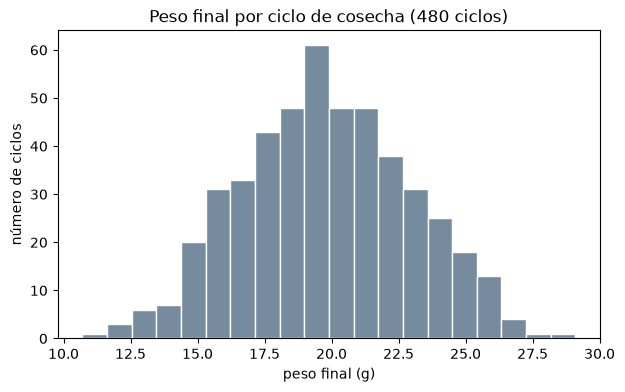

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(c["peso_g"], bins=20, color="#768B9E", edgecolor="white")
ax.set_xlabel("peso final (g)")
ax.set_ylabel("número de ciclos")
ax.set_title("Peso final por ciclo de cosecha (480 ciclos)")
plt.show()

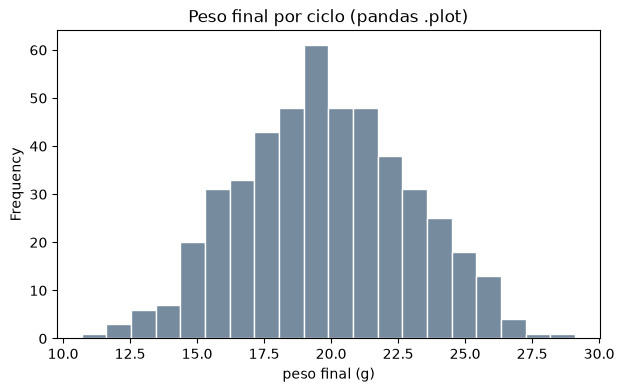

In [16]:
# El mismo gráfico con el atajo de pandas; devuelve el ax, así que las etiquetas se ponen igual
ax = c["peso_g"].plot.hist(bins=20, figsize=(7, 4), color="#768B9E", edgecolor="white")
ax.set_xlabel("peso final (g)")
ax.set_title("Peso final por ciclo (pandas .plot)")
plt.show()

### Su turno 4.1 · 5 min
Dibuje el histograma de `dias` (días de cultivo) con 15 intervalos, con etiqueta en los dos ejes (con unidad) y título. Guarde lo que devuelve `ax.hist(...)` en `conteos, bordes, barras = ax.hist(...)`: `conteos` tiene cuántos ciclos caen en cada intervalo.

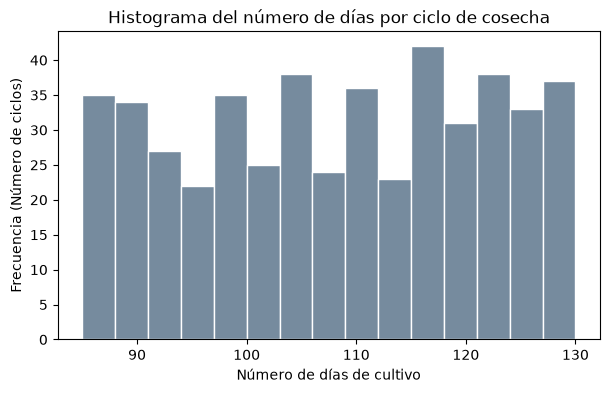

In [17]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(7, 4))
conteos, bordes, barras = ax.hist(c["dias"], bins=15, color="#768B9E", edgecolor="white")
ax.set_xlabel("Número de días de cultivo")
ax.set_ylabel("Frecuencia (Número de ciclos)")
ax.set_title("Histograma del número de días por ciclo de cosecha")
plt.show()

In [18]:
assert len(conteos) == 15 and int(conteos.sum()) == 480, "15 intervalos que suman los 480 ciclos"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
print("Correcto. El intervalo más poblado tiene", int(conteos.max()), "ciclos.")

Correcto. El intervalo más poblado tiene 42 ciclos.


## 5. El histograma: la forma de la distribución

El histograma corta el rango de la variable en **intervalos** (`bins`) y cuenta cuántos valores caen en cada uno. Lo que se lee en él:

- **Centro**: dónde se acumulan los datos. **Dispersión**: qué tan ancho es.
- **Forma**: simétrica (campana), con **cola a la derecha** (muchos valores pequeños y pocos muy grandes: ingresos, cosechas, precios) o a la izquierda; con uno o varios picos.
- **Extremos**: barras aisladas lejos del grueso.

El número de intervalos cambia lo que se ve: con muy pocos se pierde la forma; con demasiados, ruido. Empiece con 20–30 y pruebe otro. `density=True` pone proporciones en vez de conteos (útil para comparar grupos de distinto tamaño).

Una línea vertical para la media y otra para la mediana (`ax.axvline`) muestra la asimetría de un vistazo.

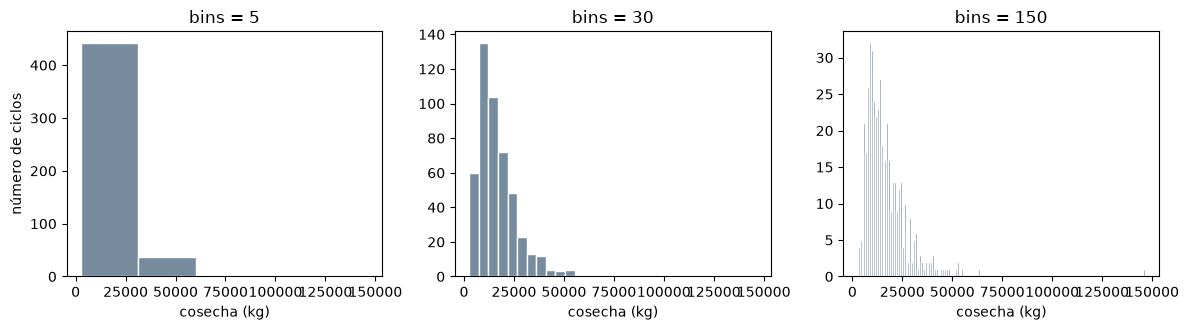

In [19]:
# Pocos, razonables y demasiados intervalos: el mismo dato, tres lecturas
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))

for ax, b in zip(axes, [5, 30, 150]):
    ax.hist(c["cosecha_kg"], bins=b, color="#768B9E", edgecolor="white")
    ax.set_title(f"bins = {b}")
    ax.set_xlabel("cosecha (kg)")
    
axes[0].set_ylabel("número de ciclos")
fig.tight_layout()
plt.show()

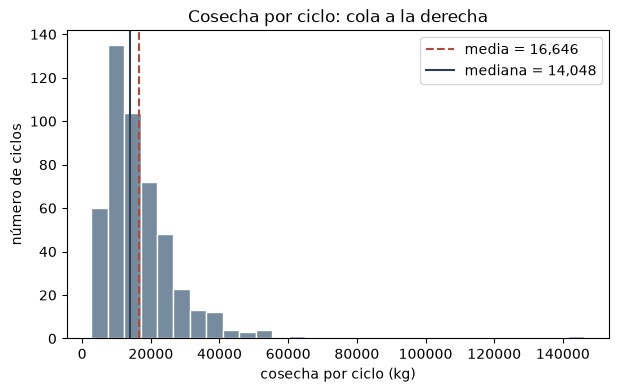

In [ ]:
# Media y mediana sobre el histograma: la media se va hacia la cola
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(c["cosecha_kg"], bins=30, color="#768B9E", edgecolor="white")
ax.axvline(c["cosecha_kg"].mean(), color="#B4483C", linestyle="--", label=f"media = {c['cosecha_kg'].mean():,.0f}")
ax.axvline(c["cosecha_kg"].median(), color="#2F3E4E", linestyle="-", label=f"mediana = {c['cosecha_kg'].median():,.0f}")
ax.set_xlabel("cosecha por ciclo (kg)")
ax.set_ylabel("número de ciclos")
ax.set_title("Cosecha por ciclo: cola a la derecha")
ax.legend()
plt.show()

### Su turno 5.1 · 4 min
Dibuje el histograma de `ingreso` de las ventas (`v`) con 25 intervalos y marque la media y la mediana con `axvline`. Guarde la media en `ing_media` y la mediana en `ing_mediana`. ¿Cuál queda a la derecha? ¿Qué forma tiene la distribución del ingreso por venta?

In [36]:
v

,fecha,producto,categoria,cantidad,precio_unitario,costo_unitario,ciudad,region,metodo_pago,tamano,ingreso,margen,mes
0,2026-01-02,Sartén,Hogar,1,18.0,11.50,Quito,Sierra,tarjeta,pequeña,18.0,6.50,1
1,2026-01-02,Mouse,Electrónica,1,15.0,9.80,Machala,Costa,efectivo,pequeña,15.0,5.20,1
2,2026-01-03,Galletas,Alimentos,2,1.8,1.10,Quito,Sierra,tarjeta,pequeña,3.6,1.40,1
3,2026-01-03,Cuaderno,Papelería,2,2.5,1.60,Guayaquil,Costa,transferencia,pequeña,5.0,1.80,1
4,2026-01-04,Cargador,Electrónica,3,12.5,7.50,Guayaquil,Costa,tarjeta,mediana,37.5,15.00,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
255,2026-04-29,Bolígrafo,Papelería,3,0.6,0.35,Cuenca,Sierra,desconocido,mediana,1.8,0.75,4
256,2026-04-29,Galletas,Alimentos,1,1.8,1.10,Machala,Costa,desconocido,pequeña,1.8,0.70,4
257,2026-04-30,Bolígrafo,Papelería,6,0.6,0.35,Cuenca,Sierra,desconocido,grande,3.6,1.50,4
258,2026-04-30,Audífonos,Electrónica,3,25.0,16.00,Guayaquil,Costa,desconocido,mediana,75.0,27.00,4


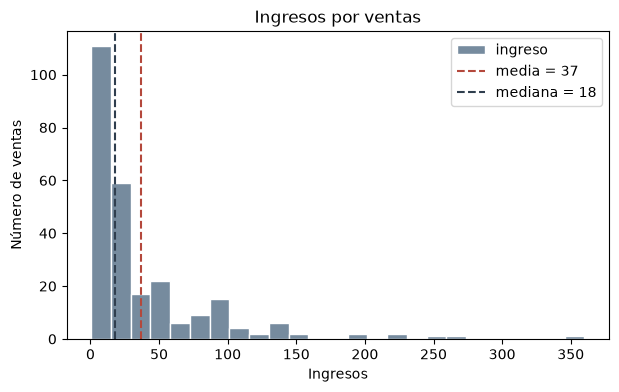

In [38]:
# TODO: reemplace los ... por su código
ing_media = v["ingreso"].mean()
ing_mediana = v["ingreso"].median()

fig, ax = plt.subplots(figsize=(7, 4))
ax = v["ingreso"].plot.hist(bins=25, figsize=(7, 4), color="#768B9E", edgecolor="white")

ax.axvline(ing_media, color="#B4483C", linestyle="--", label=f"media = {ing_media:,.0f}")
ax.axvline(ing_mediana, color="#2F3E4E", linestyle="--", label=f"mediana = {ing_mediana:,.0f}")

ax.set_xlabel("Ingresos")
ax.set_ylabel("Número de ventas")
ax.set_title("Ingresos por ventas")

ax.legend()
plt.show()

In [39]:
assert np.isclose(round(ing_media, 2), 36.52) and np.isclose(round(ing_mediana, 2), 18.0), "media y mediana de v['ingreso']"
assert ing_media > ing_mediana, "con cola a la derecha la media queda a la derecha de la mediana"
print("Correcto: media", round(ing_media, 2), "> mediana", round(ing_mediana, 2), "-> cola a la derecha (pocas ventas grandes).")

Correcto: media 36.52 > mediana 18.0 -> cola a la derecha (pocas ventas grandes).


## 6. El diagrama de caja: cuartiles y atípicos en un trazo

El diagrama de caja (*boxplot*) dibuja los **cinco números**: la caja va de Q1 a Q3 (la mitad central), la línea dentro es la **mediana**, los **bigotes** llegan hasta el último dato que está a menos de **1,5 × IQR** de la caja y los puntos de fuera son los **atípicos** (la misma regla de la sesión 7).

```
            Q1    mediana   Q3
   |---------[=======|=========]----------|      o    o        o
 bigote       ← caja: 50 % central →    bigote   atípicos (> Q3 + 1,5·IQR)
```

Es menos detallado que el histograma pero compara mejor: varias cajas lado a lado (una por zona) muestran **la misma variable por grupos**, que es el paso previo al análisis de dos variables de la sesión 11.

C:\Users\DIEGUITO TELLO\AppData\Local\Temp\ipykernel_5380\147855084.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(c["cosecha_kg"], vert=False)


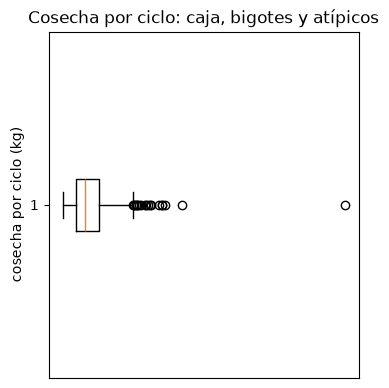

In [77]:
fig, ax = plt.subplots(figsize=(4, 4.5))
ax.boxplot(c["cosecha_kg"], vert=False)
ax.set_ylabel("cosecha por ciclo (kg)")
ax.set_xticks([])
ax.set_title("Cosecha por ciclo: caja, bigotes y atípicos")
plt.show()

In [53]:
# Los atípicos que dibuja la caja son exactamente los de la regla 1.5 x IQR
q1, q3 = c["cosecha_kg"].quantile([0.25, 0.75])
iqr = q3 - q1
limite = q3 + 1.5 * iqr
atipicos_cos = c[c["cosecha_kg"] > limite]
print("límite superior:", round(limite, 1), "| ciclos por encima:", len(atipicos_cos))
atipicos_cos.nlargest(3, "cosecha_kg")[["ciclo", "zona", "hectareas", "densidad", "supervivencia", "cosecha_kg"]]

límite superior: 38350.6 | ciclos por encima: 19


,ciclo,zona,hectareas,densidad,supervivencia,cosecha_kg
146,C-0147,Guayas,52.0,18,70.4,146286
417,C-0418,El Oro,26.7,17,73.3,63215
365,C-0366,Esmeraldas,19.5,21,63.4,55040


Un atípico **no es un error** por ser atípico: el ciclo más grande es una piscina de 52 hectáreas (real, excepcional). En la sesión 7 corregimos errores evidentes (un precio ×100); aquí los valores son legítimos y **se conservan**, pero se mencionan al describir la variable, porque arrastran la media.

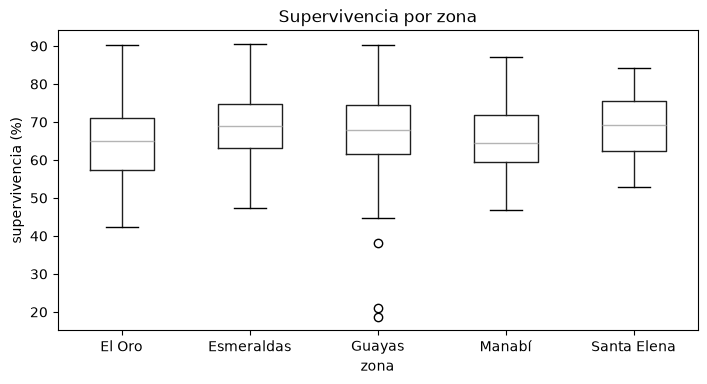

zona
El Oro         64.9
Esmeraldas     69.0
Guayas         67.9
Manabí         64.4
Santa Elena    69.2
Name: supervivencia, dtype: float64

In [42]:
# Una variable, varios grupos: supervivencia por zona (pandas construye una caja por grupo)
fig, ax = plt.subplots(figsize=(8, 4))
c.boxplot(column="supervivencia", by="zona", ax=ax, grid=False)
ax.set_xlabel("zona")
ax.set_ylabel("supervivencia (%)")
ax.set_title("Supervivencia por zona")
fig.suptitle("")           # pandas añade un título general; se quita
plt.show()
c.groupby("zona")["supervivencia"].median().round(1)

### Su turno 6.1 · 5 min
Para `ingreso` de las ventas (`v`): calcule el límite superior de la regla 1,5 × IQR en `lim_sup` y guarde en `atipicos_ing` las ventas que lo superan. Después dibuje un diagrama de caja de `ingreso` **por categoría** (`by="categoria"`), con etiquetas. ¿En qué categoría están los atípicos?

límite: 106.03 | ventas atípicas: 21


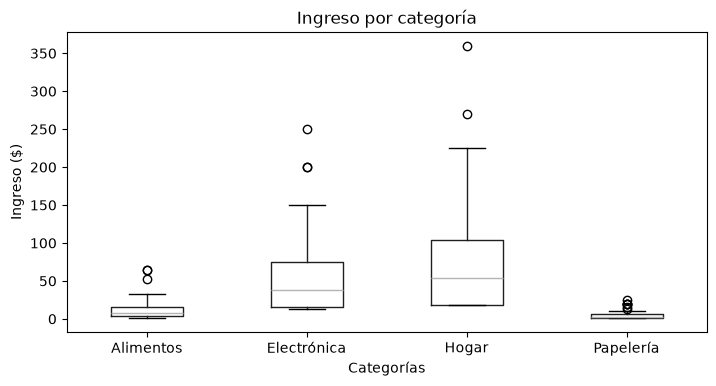

categoria
Hogar          14
Electrónica     7
Name: count, dtype: int64

In [63]:
# TODO: reemplace los ... por su código
q1, q3 = v["ingreso"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
atipicos_ing = v[v["ingreso"] > lim_sup]
print("límite:", round(lim_sup, 2), "| ventas atípicas:", len(atipicos_ing))

fig, ax = plt.subplots(figsize=(8, 4))
v.boxplot(column="ingreso", by="categoria", ax=ax, grid=False)

ax.set_xlabel("Categorías")
ax.set_ylabel("Ingreso ($)")
ax.set_title("Ingreso por categoría")

fig.suptitle("")

plt.show()
atipicos_ing["categoria"].value_counts()

In [64]:
assert np.isclose(round(lim_sup, 2), 106.03), "lim_sup = Q3 + 1.5 * (Q3 - Q1)"
assert len(atipicos_ing) == 21, f"deben ser 21 ventas por encima del límite"
print("Correcto:", len(atipicos_ing), "ventas atípicas; la mayor fue de", atipicos_ing["ingreso"].max(), "dólares. Casi todas son de", atipicos_ing["categoria"].mode().iloc[0], ".")

Correcto: 21 ventas atípicas; la mayor fue de 360.0 dólares. Casi todas son de Hogar .


### El violín: la caja con la forma de la distribución

La caja resume cada grupo en cinco números. El **violín** (*violin plot*) dibuja, además, la **forma** de cada grupo: es un histograma suavizado, puesto de pie y reflejado. Donde el violín es **ancho** hay muchos datos; donde es **estrecho**, pocos; una **punta larga y fina** es una cola con valores extremos.

- Caja: para comparar medianas y contar atípicos.
- Violín: para ver la forma (dos picos, colas, dónde se concentran los datos).
- Con **pocos datos** por grupo (menos de 30) el violín engaña: use la caja.

matplotlib recibe una **lista de columnas**, una por grupo; los nombres de los grupos se ponen con `set_xticks`.

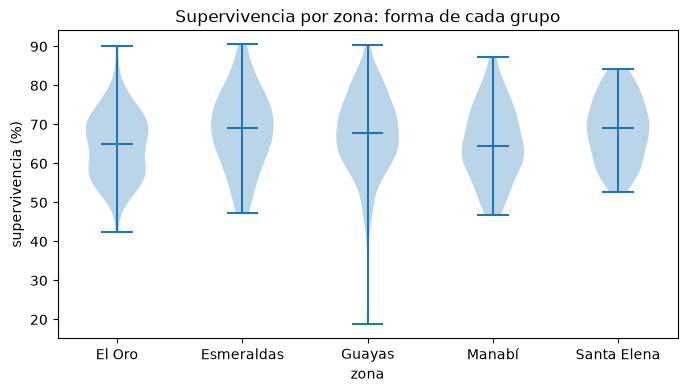

In [ ]:
# La misma variable y los mismos grupos que la caja anterior, como violines
nombres = sorted(c["zona"].unique())                              # un nombre por grupo
grupos = [c.loc[c["zona"] == z, "supervivencia"] for z in nombres]  # una columna por grupo

fig, ax = plt.subplots(figsize=(8, 4))
ax.violinplot(grupos, showmedians=True)

ax.set_xticks(range(1, len(nombres) + 1), labels=nombres)
ax.set_xlabel("zona")
ax.set_ylabel("supervivencia (%)")
ax.set_title("Supervivencia por zona: forma de cada grupo")

plt.show()

Lectura: las cinco zonas se concentran entre 60 y 75 %; **Guayas** tiene una punta larga hacia abajo: son los tres ciclos de la caja anterior (menos de 40 %). El violín los muestra como una cola; la caja, como puntos.

### Su turno 6.2 · 3 min
Repita la caja de «Su turno 6.1» como violín: `ingreso` por `categoria` en `v`. Guarde los nombres en `nombres_cat` (ordenados) y las columnas en `grupos_ing`. ¿Qué forma tienen las cuatro categorías? ¿Cuál tiene la punta más larga?

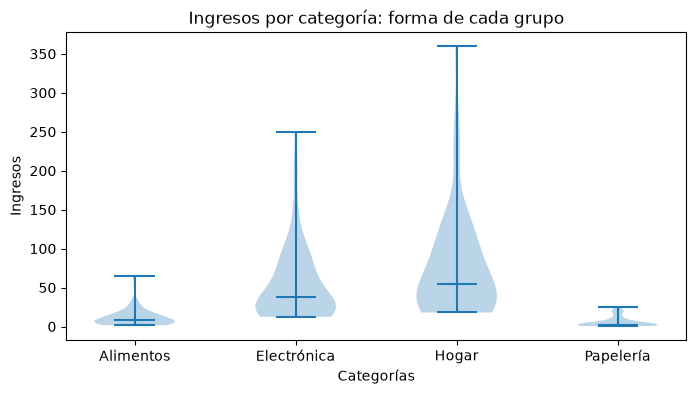

In [83]:
# TODO: reemplace los ... por su código
nombres_cat = sorted(v["categoria"].unique())
grupos_ing = [v.loc[v["categoria"] == k, "ingreso"] for k in nombres_cat]

fig, ax = plt.subplots(figsize=(8, 4))
ax.violinplot(grupos_ing, showmedians=True)
ax.set_xticks(range(1, len(nombres_cat) + 1), labels=nombres_cat)
ax.set_xlabel("Categorías")
ax.set_ylabel("Ingresos")
ax.set_title("Ingresos por categoría: forma de cada grupo")
plt.show()

In [84]:
assert nombres_cat == ['Alimentos', 'Electrónica', 'Hogar', 'Papelería'], "nombres_cat: las categorías, ordenadas"
assert [len(g) for g in grupos_ing] == [84, 77, 54, 45], "una columna de ingreso por categoría, en el orden de nombres_cat"
print("Correcto: cuatro violines con cola hacia arriba (cola a la derecha); la punta más larga es la de", max(zip(grupos_ing, nombres_cat), key=lambda t: t[0].max())[1] + ".")

Correcto: cuatro violines con cola hacia arriba (cola a la derecha); la punta más larga es la de Hogar.


## 7. Barras para las categóricas (y por qué no un pastel)

El gráfico de una tabla de frecuencias es el de **barras**: una barra por categoría, altura = frecuencia. Reglas:

- Nominal: barras **ordenadas** de mayor a menor (`value_counts` ya lo hace). Ordinal: **en su orden**.
- Etiquetas largas: barras horizontales (`barh`, o `plot.barh()`).
- El eje de las frecuencias **empieza en cero**; si no, las diferencias se exageran.
- **Nada de pasteles** en este curso: el ojo compara mal ángulos y áreas; compara bien longitudes. Todo lo que dice un pastel lo dice mejor una barra.

Un histograma es para numéricas (los intervalos son contiguos); las barras, para categorías (separadas). No se mezclan.

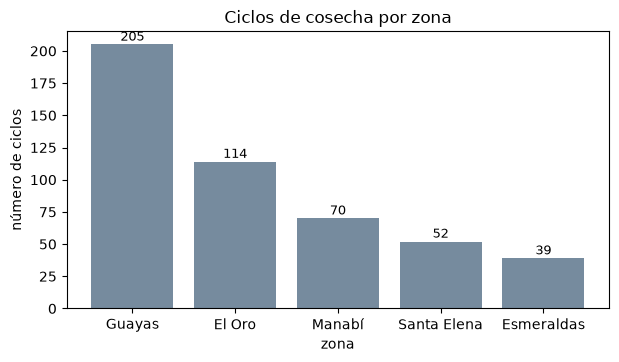

In [ ]:
frec = c["zona"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(frec.index, frec.values, color="#768B9E")
ax.set_xlabel("zona")
ax.set_ylabel("número de ciclos")
ax.set_title("Ciclos de cosecha por zona")
for i, n in enumerate(frec.values):           # el valor encima de cada barra
    ax.text(i, n + 3, str(n), ha="center", fontsize=9)
plt.show()

C:\Users\DIEGUITO TELLO\AppData\Local\Temp\ipykernel_5380\147855084.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(c["cosecha_kg"], vert=False)


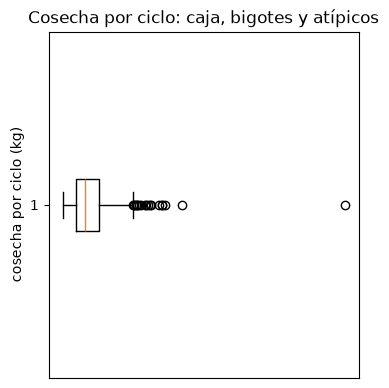

In [100]:
fig, ax = plt.subplots(figsize=(4, 4.5))
ax.boxplot(c["cosecha_kg"], vert=False)
ax.set_ylabel("cosecha por ciclo (kg)")
ax.set_xticks([])
ax.set_title("Cosecha por ciclo: caja, bigotes y atípicos")
plt.show()

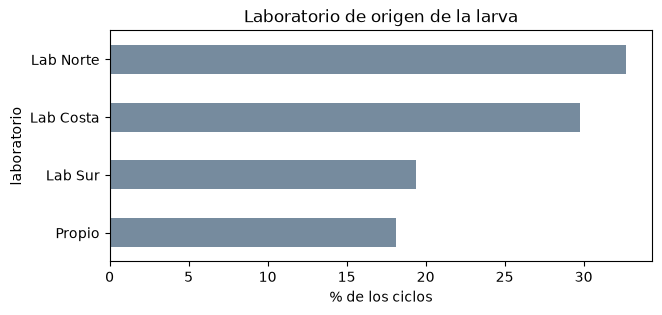

In [101]:
# Con pandas, en porcentaje y horizontal: dos líneas
pct = (c["laboratorio"].value_counts(normalize=True) * 100).round(1)
ax = pct.sort_values().plot.barh(figsize=(7, 3), color="#768B9E")
ax.set_xlabel("% de los ciclos")
ax.set_title("Laboratorio de origen de la larva")
plt.show()

### Su turno 7.1 · 4 min
Dibuje las barras del **porcentaje** de ventas por `metodo_pago` (tabla `v`), ordenadas de mayor a menor, con etiquetas y título. Guarde los porcentajes (redondeados a 1 decimal) en `pct_pago`.

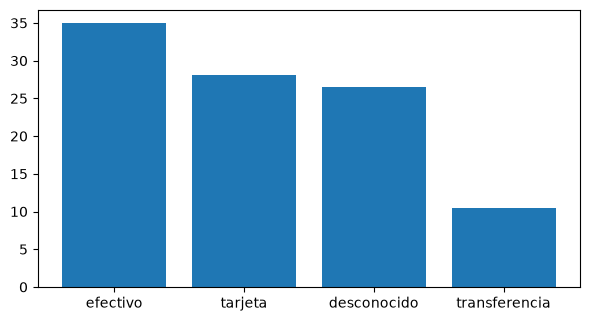

In [111]:
# TODO: reemplace los ... por su código
pct_pago = round(v["metodo_pago"].value_counts(normalize=True)* 100, 1) 
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(v["metodo_pago"].value_counts().index, pct_pago.values)
plt.show()

In [112]:
assert pct_pago.round(1).to_dict() == {'efectivo': 35.0, 'tarjeta': 28.1, 'desconocido': 26.5, 'transferencia': 10.4}, "value_counts(normalize=True) * 100, redondeado a 1 decimal"
assert pct_pago.index[0] == "efectivo", "ordene de mayor a menor"
print("Correcto. El método más frecuente es", pct_pago.index[0], "con el", pct_pago.iloc[0], "% de las ventas.")

Correcto. El método más frecuente es efectivo con el 35.0 % de las ventas.


## 8. Un panel con varios gráficos y cómo guardarlo

`plt.subplots(filas, columnas)` devuelve una **matriz de ejes**: `axes[0, 0]` es el de arriba a la izquierda. `fig.tight_layout()` evita que las etiquetas se pisen y `fig.savefig(...)` guarda la figura como imagen (`dpi=150` para pantalla y documentos; `bbox_inches="tight"` recorta los márgenes). Guardar **antes** de `plt.show()`.

In [ ]:
import os
os.makedirs("figuras", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(c["cosecha_kg"], bins=30, color="#768B9E", edgecolor="white")
axes[0, 0].set_title("Cosecha por ciclo (kg): cola a la derecha")
axes[0, 0].set_xlabel("kg"); axes[0, 0].set_ylabel("ciclos")

axes[0, 1].hist(c["supervivencia"], bins=25, color="#768B9E", edgecolor="white")
axes[0, 1].set_title("Supervivencia (%): aproximadamente simétrica")
axes[0, 1].set_xlabel("%"); axes[0, 1].set_ylabel("ciclos")

axes[1, 0].boxplot(c["peso_g"])
axes[1, 0].set_title("Peso final (g): caja y bigotes")
axes[1, 0].set_ylabel("g"); axes[1, 0].set_xticks([])

frec = c["zona"].value_counts()
axes[1, 1].bar(frec.index, frec.values, color="#768B9E")
axes[1, 1].set_title("Ciclos por zona")
axes[1, 1].set_ylabel("ciclos")

fig.suptitle("Cosechas 2024-2025: descripción de cuatro variables", fontsize=13)
fig.tight_layout()
fig.savefig("figuras/cosechas_univariado.png", dpi=150, bbox_inches="tight")
plt.show()
print("guardado en figuras/cosechas_univariado.png")

**Lo que dice cada gráfico, en una frase** (así se comenta un gráfico en la Entrega 1 del proyecto):

- *Cosecha por ciclo*: la mayoría de los ciclos produce entre 5 000 y 25 000 kg; unos pocos superan los 50 000 (piscinas muy grandes) y arrastran la media (16 646 kg) por encima de la mediana (14 048 kg).
- *Supervivencia*: centrada en 67 %, casi simétrica, con tres ciclos por debajo del 40 % que merecen revisarse.
- *Peso final*: la mitad de los ciclos cosecha entre 17,5 y 22 g; solo dos valores (10,7 y 29,1 g) quedan fuera de los bigotes, apenas.
- *Zona*: Guayas concentra el 43 % de los ciclos; El Oro, el 24 %.

Cada frase tiene **un número** y **una lectura**. Ninguna repite lo que ya se ve («las barras tienen distintas alturas»).

## 9. Errores frecuentes

| Síntoma | Causa | Solución |
| :-- | :-- | :-- |
| el histograma es un bloque o un peine | muy pocos o demasiados `bins` | pruebe 20–30 y ajuste |
| histograma de una categórica (`TypeError` o barras sin sentido) | `hist` espera números | `value_counts().plot.bar()` |
| barras de una numérica continua (cientos de barras) | `bar` dibuja una por valor distinto | histograma, o `cut` y luego barras |
| gráfico sin etiquetas ni unidades | se omitieron `set_xlabel`, `set_ylabel`, `set_title` | obligatorias |
| las diferencias entre barras parecen enormes | el eje y no empieza en cero | `ax.set_ylim(0, ...)` |
| dos histogramas no se pueden comparar | `bins` distintos o grupos de tamaño distinto | mismos `bins=` explícitos; `density=True` |
| la imagen guardada sale en blanco | `savefig` después de `plt.show()` | guardar antes de mostrar |
| aparece un título «Boxplot grouped by …» | pandas lo añade con `by=` | `fig.suptitle("")` |
| la media «no representa» a los datos | cola larga o atípicos | reporte también la mediana y el IQR |

## 10. Hacia el proyecto: describir sus variables

La **Entrega 1** del proyecto (sesión 14) pide, entre otras cosas, la descripción univariada de las variables principales y las preguntas de negocio respondidas con una tabla y un gráfico. Todo eso ya lo saben hacer:

| Parte de la Entrega 1 | Herramienta | Sesión |
| :-- | :-- | :-- |
| describir las variables principales (numéricas y categóricas) | descriptivos, tablas de frecuencia, histograma, caja, barras, **una frase por variable** | hoy |
| responder las preguntas de negocio con una tabla y un gráfico cada una | `groupby`/`pivot_table`/`crosstab` + barras, **una interpretación por pregunta** | 8, 9 y hoy |
| los KPIs calculados | agregaciones | 8 |
| preparar la tabla (columnas derivadas, categorías, unión de archivos) | `map`, `cut`, `merge`, `concat` | 9 |
| correlaciones y serie de tiempo | se ven en las sesiones 11 y 12 | 11, 12 |

### Ahora, con su conjunto de datos · 10 min
Con la tabla limpia de la Tarea 1: elija **una variable numérica** que use alguna de sus preguntas y descríbala como en la sección 8: descriptivos (`agg`), histograma o diagrama de caja con título y etiquetas, atípicos por la regla 1,5 × IQR y **una frase** con un número y una lectura.

In [ ]:
# Con su conjunto de datos (complete con sus columnas)
# datos = pd.read_csv("datos/mi_dataset_limpio.csv")
# col = "columna_numerica"
# print(datos[col].agg(["mean", "median", "std", "min", "max", "skew"]).round(2))
# q1, q3 = datos[col].quantile([0.25, 0.75]); print("atípicos:", ((datos[col] > q3 + 1.5 * (q3 - q1)) | (datos[col] < q1 - 1.5 * (q3 - q1))).sum())
# fig, ax = plt.subplots(figsize=(7, 4)); ax.hist(datos[col], bins=25); ax.set_xlabel("... (unidad)"); ax.set_ylabel("número de ..."); ax.set_title("...")

### Su turno 10.1 · en casa
Describa **dos variables más** de su conjunto de datos: una numérica (descriptivos + histograma o caja + atípicos) y una categórica (tabla de frecuencias con n y % + barras ordenadas), cada una con su frase de lectura. Traiga el notebook a la sesión 11.

In [ ]:
# Categórica (complete con sus columnas)
# frec = pd.DataFrame({"n": datos["columna_categorica"].value_counts(),
#                      "pct": (datos["columna_categorica"].value_counts(normalize=True) * 100).round(1)})
# ax = frec["pct"].plot.bar(figsize=(7, 3.6)); ax.set_ylabel("% de las filas"); ax.set_title("...")

**Antes de la próxima sesión (S11, Taller 3):** la S11 compara variables entre sí (correlación de Pearson y Spearman, mapa de calor, *pairplot*) y es el tercer taller calificado. Repase hoy: histograma, caja y barras con etiquetas. Lecturas: McKinney cap. 5 §5.3 («Resumir y calcular estadísticas descriptivas») y cap. 9 §9.1 («Introducción a la API de matplotlib»); VanderPlas cap. 4, «Simple Line Plots» y «Histograms, Binnings, and Density».